# 04 · Feature understanding and reduction

**Requirement covered:** *"Features to be understood and to be seen if one can reduce"* and *"Feature reduction: correlation filter, PCA or feature importance"*.

We do **all three** methods named on the slide, plus VIF and mutual information, and then **prove** whether reducing the features hurts accuracy.

**Leakage-safe protocol**
* Everything that *learns from data* (correlations, importances, PCA, imputers) is fitted on the **training period only**.
* Feature **selection** uses a *validation year* inside the training period: fit on 2015-2017, validate on 2018.
* The **test period (2019 → Jul 2020)** is only used at the end, to report the final before/after table. It does not influence which features are chosen.

Task: same-day regression of `AQI` from pollutants + calendar + event + city features. Selection model: a fast Gradient Boosting model with fixed settings, plus Linear Regression and a small Random Forest for comparison.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from src import db, config, features, modeling, evaluate
from src.config import MODEL_POLLUTANTS, LABELS, TEST_START, VALID_START, RANDOM_STATE
from src.viz import set_style, save_fig
set_style(); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

conn = db.get_conn()
df = pd.read_sql_query("SELECT * FROM aqi_features", conn, parse_dates=["date"])
pop = df[df.in_model_pop == 1].copy()

POLL = MODEL_POLLUTANTS
NUM_ALL = POLL + features.CALENDAR_FEATURES + features.EVENT_FEATURES
CAT_ALL = features.CATEGORICAL_FEATURES                      # season, city
ALL_LOGICAL = NUM_ALL + CAT_ALL

train, test = modeling.time_split(pop, TEST_START)
fs_train = train[train.date < VALID_START]; fs_valid = train[train.date >= VALID_START]
print(f"selection-train {len(fs_train):,} rows (2015-2017) | validation {len(fs_valid):,} rows (2018) | final train {len(train):,} | test {len(test):,}")
print(f"{len(ALL_LOGICAL)} candidate features: {len(POLL)} pollutants + {len(features.CALENDAR_FEATURES)} calendar + {len(features.EVENT_FEATURES)} event + season + city")

selection-train 7,185 rows (2015-2017) | validation 5,356 rows (2018) | final train 12,541 | test 10,959
23 candidate features: 11 pollutants + 5 calendar + 5 event + season + city


## 1 · Feature inventory

In [2]:
inv = pd.DataFrame({"group": ["pollutant"] * len(POLL) + ["calendar"] * len(features.CALENDAR_FEATURES) + ["event"] * len(features.EVENT_FEATURES) + ["categorical", "categorical"],
                    "feature": ALL_LOGICAL})
inv["type"] = np.where(inv.feature.isin(CAT_ALL), "categorical", "numeric")
inv["% missing (train)"] = [round(fs_train[f].isna().mean() * 100, 1) for f in inv.feature]
inv["n_unique"] = [fs_train[f].nunique() for f in inv.feature]
inv

,group,feature,type,% missing (train),n_unique
0,pollutant,pm25,numeric,1.4,5668
1,pollutant,pm10,numeric,50.0,3272
2,pollutant,no_,numeric,0.7,3131
3,pollutant,no2,numeric,0.6,4246
4,pollutant,nox,numeric,18.5,3568
5,pollutant,nh3,numeric,39.2,3102
6,pollutant,co,numeric,4.5,768
7,pollutant,so2,numeric,1.5,2248
8,pollutant,o3,numeric,2.5,4495
9,pollutant,benzene,numeric,15.1,947


## 2 · Univariate relevance – correlation and mutual information
Spearman correlation catches monotone relations, **mutual information** (MI) also catches non-linear ones.

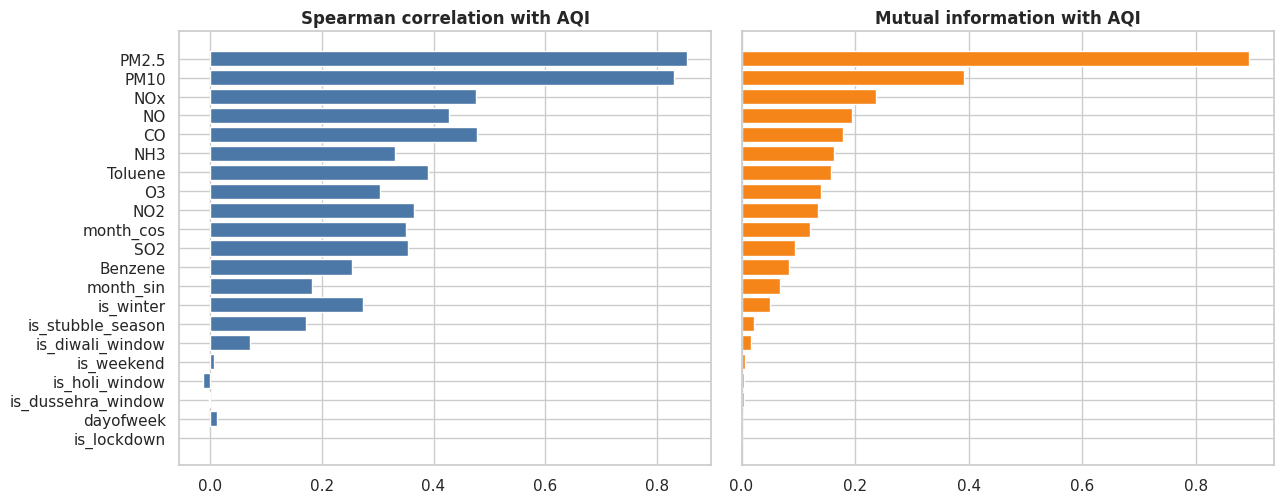

,spearman_with_AQI,mutual_info
pm25,0.854,0.893
pm10,0.831,0.392
nox,0.476,0.236
no_,0.427,0.195
co,0.478,0.179
nh3,0.330,0.162
toluene,0.390,0.157
o3,0.304,0.140
no2,0.365,0.135
month_cos,0.350,0.121


In [3]:
Xn = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(fs_train[NUM_ALL]), columns=NUM_ALL, index=fs_train.index)
spear = fs_train[NUM_ALL].corrwith(fs_train["aqi"], method="spearman")
mi = pd.Series(mutual_info_regression(Xn, fs_train["aqi"], random_state=RANDOM_STATE), index=NUM_ALL)
rel = pd.DataFrame({"spearman_with_AQI": spear, "mutual_info": mi}).sort_values("mutual_info", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
order = rel.index
axes[0].barh([LABELS.get(i, i) for i in order], rel.loc[order, "spearman_with_AQI"], color="#4c78a8"); axes[0].set_title("Spearman correlation with AQI"); axes[0].invert_yaxis()
axes[1].barh([LABELS.get(i, i) for i in order], rel.loc[order, "mutual_info"], color="#f58518"); axes[1].set_title("Mutual information with AQI")
plt.tight_layout(); save_fig("04_feature_relevance"); plt.show()
rel.round(3)

## 3 · Redundancy – correlation matrix and VIF
Highly correlated predictors carry the same information. The **variance inflation factor** VIF = 1 / (1 − R²) of regressing a feature on all the others; > 5 is often considered problematic, > 10 severe.

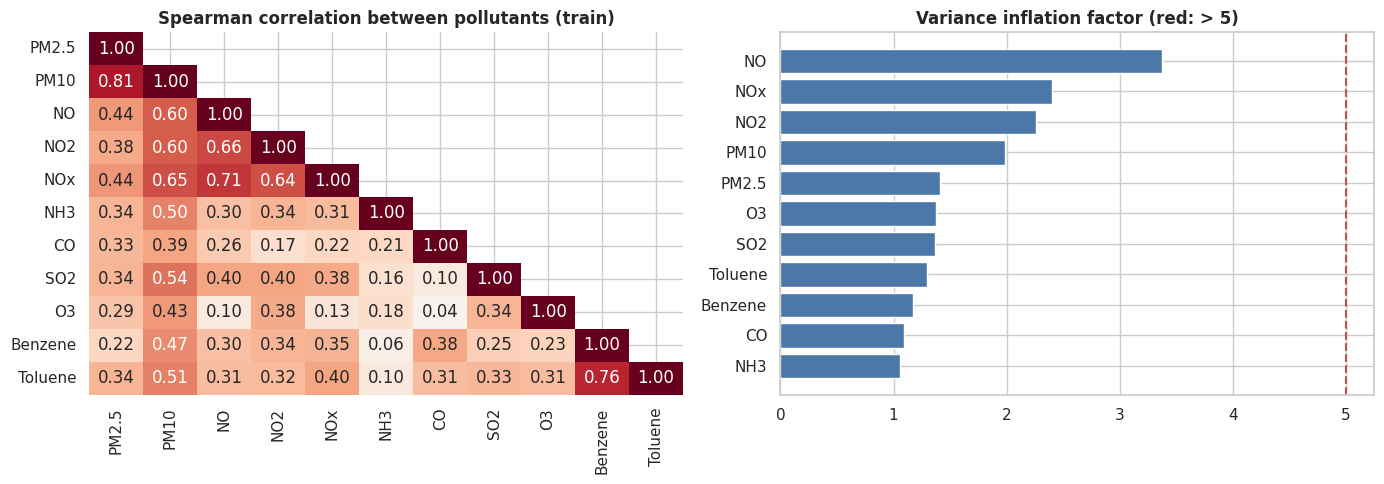

,NO,NOx,NO2,PM10,PM2.5,O3,SO2,Toluene,Benzene,CO,NH3
VIF,3.37,2.4,2.26,1.99,1.42,1.38,1.36,1.3,1.17,1.09,1.05


In [4]:
P = pd.DataFrame(StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(fs_train[POLL])), columns=POLL)
vif = pd.Series({c: 1 / (1 - LinearRegression().fit(P.drop(columns=c), P[c]).score(P.drop(columns=c), P[c])) for c in POLL}).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = fs_train[POLL].corr(method="spearman").rename(index=LABELS, columns=LABELS)
sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool), 1), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False); axes[0].set_title("Spearman correlation between pollutants (train)")
axes[1].barh([LABELS[i] for i in vif.index], vif.values, color=["#d62728" if v > 5 else "#4c78a8" for v in vif.values]); axes[1].axvline(5, color="r", ls="--"); axes[1].invert_yaxis(); axes[1].set_title("Variance inflation factor (red: > 5)")
plt.tight_layout(); save_fig("04_correlation_vif"); plt.show()
vif.round(2).rename(index=LABELS).to_frame("VIF").T

## 4 · Method A – correlation filter
Greedy rule: rank pollutants by |Spearman| with AQI; keep a feature unless it is correlated more than **0.75** with an already kept one (ties are broken by lower missingness); also drop features with |ρ| < 0.10 with the target. Calendar, event and categorical features are kept untouched.

In [5]:
def correlation_filter(data, cols, target="aqi", redundancy=0.75, min_target=0.10):
    corr_t = data[cols].corrwith(data[target], method="spearman").abs()
    miss = data[cols].isna().mean()
    order = sorted(cols, key=lambda c: (-round(corr_t[c], 2), miss[c]))
    cc = data[cols].corr(method="spearman").abs()
    kept, dropped = [], {}
    for c in order:
        if corr_t[c] < min_target: dropped[c] = f"weak target correlation ({corr_t[c]:.2f})"; continue
        clash = [k for k in kept if cc.loc[c, k] > redundancy]
        if clash: dropped[c] = f"redundant with {LABELS[clash[0]]} (ρ={cc.loc[c, clash[0]]:.2f})"; continue
        kept.append(c)
    return kept, dropped
kept_poll, dropped_poll = correlation_filter(fs_train, POLL)
CORR_SET = kept_poll + features.CALENDAR_FEATURES + features.EVENT_FEATURES + CAT_ALL
print("kept pollutants   :", [LABELS[c] for c in kept_poll])
for c, why in dropped_poll.items(): print(f"dropped {LABELS[c]:<8}: {why}")
print(f"→ correlation-filter set: {len(CORR_SET)} of {len(ALL_LOGICAL)} features")

kept pollutants   : ['PM2.5', 'CO', 'NOx', 'NO', 'Toluene', 'NO2', 'SO2', 'NH3', 'O3']
dropped PM10    : redundant with PM2.5 (ρ=0.81)
dropped Benzene : redundant with Toluene (ρ=0.76)
→ correlation-filter set: 21 of 23 features


## 5 · Method B – model-based importance
Two views: **permutation importance** (how much does the validation error grow when a feature is shuffled? – model-agnostic and unbiased toward high-cardinality features) and the Random Forest's **impurity importance** (aggregated back to the original features).

Gradient Boosting, all features – validation 2018: {'MAE': 24.947, 'RMSE': 39.734, 'R2': 0.841}


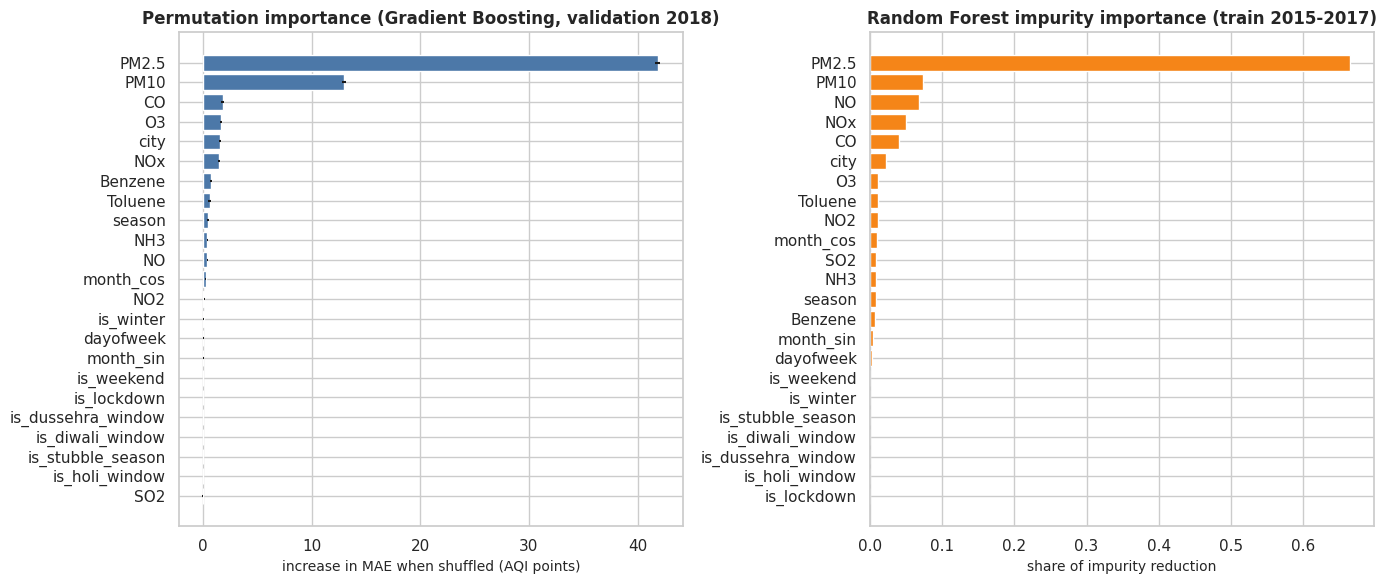

,permutation_ΔMAE,rf_impurity_%
pm25,41.85,66.5
pm10,12.99,7.3
co,1.83,4.0
o3,1.63,1.1
city,1.59,2.3
nox,1.46,5.0
benzene,0.74,0.7
toluene,0.62,1.1
season,0.48,0.8
nh3,0.40,0.8


In [6]:
def make_model(name):
    if name == "Linear Regression": return LinearRegression(), "linear"
    if name == "Gradient Boosting": return HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, random_state=RANDOM_STATE), "tree"
    if name == "Random Forest":     return RandomForestRegressor(n_estimators=80, min_samples_leaf=3, max_features=0.5, max_samples=0.7, n_jobs=-1, random_state=RANDOM_STATE), "tree"

def split_cols(feats): return [f for f in feats if f in NUM_ALL], [f for f in feats if f in CAT_ALL]

def build(feats, model, pca=None):
    est, kind = make_model(model); num, cat = split_cols(feats)
    if pca: return modeling.make_pipeline(est, num, cat, "linear", pca_cols=[p for p in POLL if p in num], n_pca=pca)
    return modeling.make_pipeline(est, num, cat, kind)

def fit_eval(feats, model, tr, te, pca=None):
    num, cat = split_cols(feats); pipe = build(feats, model, pca).fit(tr[num + cat], tr["aqi"])
    return evaluate.regression_metrics(te["aqi"], pipe.predict(te[num + cat])), pipe

m_full, gb_full = fit_eval(ALL_LOGICAL, "Gradient Boosting", fs_train, fs_valid)
print("Gradient Boosting, all features – validation 2018:", {k: round(v, 3) for k, v in m_full.items()})
pi = permutation_importance(gb_full, fs_valid[ALL_LOGICAL], fs_valid["aqi"], scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_STATE)
perm = pd.Series(pi.importances_mean, index=ALL_LOGICAL).sort_values(ascending=False)
perm_sd = pd.Series(pi.importances_std, index=ALL_LOGICAL)

_, rf_full = fit_eval(ALL_LOGICAL, "Random Forest", fs_train, fs_valid)
names = rf_full.named_steps["prep"].get_feature_names_out(); imp = pd.Series(rf_full.named_steps["model"].feature_importances_, index=names)
def logical(n): n = n.split("__", 1)[1]; return "city" if n.startswith("city_") else ("season" if n.startswith("season_") else n)
rf_imp = imp.groupby(imp.index.map(logical)).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh([LABELS.get(i, i) for i in perm.index], perm.values, xerr=perm_sd[perm.index].values, color="#4c78a8"); axes[0].invert_yaxis(); axes[0].set_xlabel("increase in MAE when shuffled (AQI points)"); axes[0].set_title("Permutation importance (Gradient Boosting, validation 2018)")
axes[1].barh([LABELS.get(i, i) for i in rf_imp.index], rf_imp.values, color="#f58518"); axes[1].invert_yaxis(); axes[1].set_xlabel("share of impurity reduction"); axes[1].set_title("Random Forest impurity importance (train 2015-2017)")
plt.tight_layout(); save_fig("04_importance"); plt.show()
pd.DataFrame({"permutation_ΔMAE": perm.round(2), "rf_impurity_%": (rf_imp * 100).round(1)}).sort_values("permutation_ΔMAE", ascending=False)

### 5.1 How many features do we really need?
Add features one at a time in order of permutation importance and watch the error. We draw **two** curves:

* **single validation year (2018)** – our first, naive protocol;
* **4-fold expanding-window time-series CV over the whole training period (2015-2018)** – a more stable protocol.

The smallest set within **0.005 R²** of the full model is the "importance set".

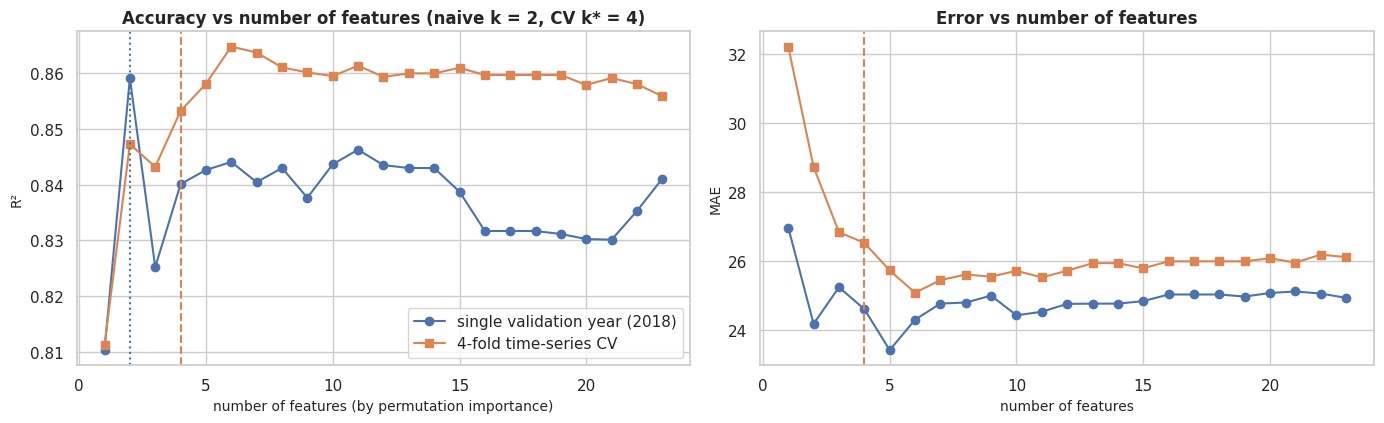

naive single-year choice : k = 2  ['PM2.5', 'PM10']
CV-based choice (used)   : k* = 4  ['PM2.5', 'PM10', 'CO', 'O3']
CV R²: full = 0.8559, top-4 = 0.8533


,k,added,val2018_R2,val2018_MAE,cv_R2,cv_MAE
0,1,pm25,0.810,26.977,0.811,32.229
1,2,pm10,0.859,24.186,0.847,28.734
2,3,co,0.825,25.247,0.843,26.844
3,4,o3,0.840,24.611,0.853,26.534
4,5,city,0.843,23.424,0.858,25.734
5,6,nox,0.844,24.306,0.865,25.087
6,7,benzene,0.840,24.772,0.864,25.453
7,8,toluene,0.843,24.802,0.861,25.614
8,9,season,0.838,25.004,0.860,25.556
9,10,nh3,0.844,24.433,0.860,25.723


In [7]:
from sklearn.model_selection import TimeSeriesSplit
rank = list(perm.index)
train_sorted = train.sort_values("date").reset_index(drop=True)
folds = list(TimeSeriesSplit(n_splits=4).split(train_sorted))

def cv_r2(feats, model="Gradient Boosting", pca=None):
    r = [fit_eval(feats, model, train_sorted.iloc[a], train_sorted.iloc[b], pca)[0] for a, b in folds]
    return pd.DataFrame(r).mean()

rows = []
for k in range(1, len(rank) + 1):
    m1, _ = fit_eval(rank[:k], "Gradient Boosting", fs_train, fs_valid); mc = cv_r2(rank[:k])
    rows.append({"k": k, "added": rank[k - 1], "val2018_R2": m1["R2"], "val2018_MAE": m1["MAE"], "cv_R2": mc["R2"], "cv_MAE": mc["MAE"]})
curve = pd.DataFrame(rows); TOL = 0.005
k_naive = int(curve[curve.val2018_R2 >= curve.val2018_R2.iloc[-1] - TOL].k.min())
k_star = int(curve[curve.cv_R2 >= curve.cv_R2.iloc[-1] - TOL].k.min())
IMP_SET = rank[:k_star]; NAIVE_SET = rank[:k_naive]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].plot(curve.k, curve.val2018_R2, marker="o", label="single validation year (2018)"); axes[0].plot(curve.k, curve.cv_R2, marker="s", label="4-fold time-series CV")
axes[0].axvline(k_naive, color="C0", ls=":"); axes[0].axvline(k_star, color="C1", ls="--"); axes[0].set_xlabel("number of features (by permutation importance)"); axes[0].set_ylabel("R²"); axes[0].legend(); axes[0].set_title(f"Accuracy vs number of features (naive k = {k_naive}, CV k* = {k_star})")
axes[1].plot(curve.k, curve.val2018_MAE, marker="o"); axes[1].plot(curve.k, curve.cv_MAE, marker="s"); axes[1].axvline(k_star, color="C1", ls="--"); axes[1].set_xlabel("number of features"); axes[1].set_ylabel("MAE"); axes[1].set_title("Error vs number of features")
plt.tight_layout(); save_fig("04_k_curve"); plt.show()
print(f"naive single-year choice : k = {k_naive}  {[LABELS.get(f, f) for f in NAIVE_SET]}")
print(f"CV-based choice (used)   : k* = {k_star}  {[LABELS.get(f, f) for f in IMP_SET]}")
print(f"CV R²: full = {curve.cv_R2.iloc[-1]:.4f}, top-{k_star} = {curve.cv_R2.iloc[k_star - 1]:.4f}")
curve.round(3)

> **Transparency note.** Our first run used only the 2018 validation year and picked just two features. Its k-curve is jagged (R² goes up *and* down as features are added), a typical sign that one validation year is too noisy – and when we later looked at the test period that two-feature set was worse than the full model. We therefore switched to multi-fold time-series CV, which is the better-practice protocol anyway. Because that switch happened *after* seeing the test result, we keep the naive set in the final table as a labelled comparison rather than hiding it.

## 6 · Method C – PCA on the pollutants
PCA is fitted on the standardised, median-imputed **pollutants of the training period**. It compresses correlated pollutants into a few orthogonal components – at the cost of interpretability.

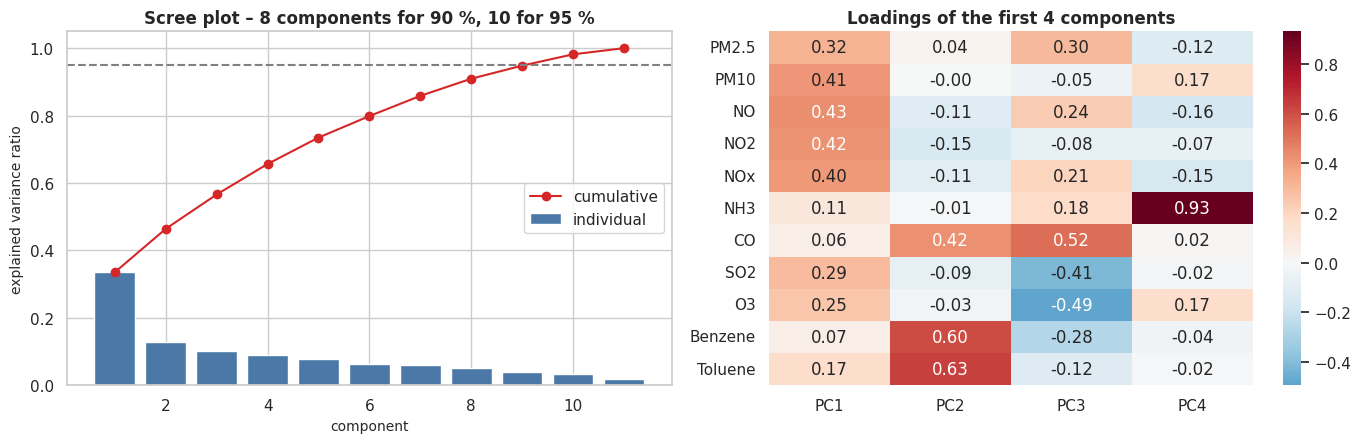

PCA: 10 components keep 95 % of the pollutant variance (from 11 pollutants)


In [8]:
pca = PCA(random_state=RANDOM_STATE).fit(P)
ev = pca.explained_variance_ratio_; cum = ev.cumsum()
n90, n95 = int((cum < 0.90).sum() + 1), int((cum < 0.95).sum() + 1)
load = pd.DataFrame(pca.components_[:4].T, index=[LABELS[c] for c in POLL], columns=[f"PC{i + 1}" for i in range(4)])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].bar(range(1, len(ev) + 1), ev, color="#4c78a8", label="individual"); axes[0].plot(range(1, len(ev) + 1), cum, "o-", color="#d62728", label="cumulative")
axes[0].axhline(0.95, color="grey", ls="--"); axes[0].set_xlabel("component"); axes[0].set_ylabel("explained variance ratio"); axes[0].legend(); axes[0].set_title(f"Scree plot – {n90} components for 90 %, {n95} for 95 %")
sns.heatmap(load, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1]); axes[1].set_title("Loadings of the first 4 components")
plt.tight_layout(); save_fig("04_pca"); plt.show()
print(f"PCA: {n95} components keep 95 % of the pollutant variance (from {len(POLL)} pollutants)")

**Reading the PCA:** PC1 (33 % of the variance) is a *traffic / combustion* axis – PM10, NO, NO2, NOx and PM2.5 load together. PC2 (13 %) is a *CO + volatile-organics* axis (Benzene, Toluene, CO). PC3 contrasts CO / PM2.5 with O3 and SO2. The variance is spread over many components (**10 are needed for 95 %**), i.e. the pollutants are *not* very redundant – consistent with the low VIFs (all < 3.4). PCA also optimises *variance*, not *relevance to the AQI*, which is why it does not help below.

## 7 · Before / after: does reducing features hurt?
Four feature sets × three models, evaluated twice: on the **validation year** (used for the decision) and on the **test period** (final report, fit on the full training period).

In [9]:
sets = {"FULL": (ALL_LOGICAL, None), "CORRELATION FILTER": (CORR_SET, None), f"IMPORTANCE top-{k_star} (CV)": (IMP_SET, None),
        f"PCA ({n95} comp. + non-pollutants)": (ALL_LOGICAL, n95)}
if k_naive != k_star:
    sets[f"IMPORTANCE top-{k_naive} (naive 1-year pick)"] = (NAIVE_SET, None)
rows, log_rows = [], []
for sname, (feats, pc) in sets.items():
    for model in ["Linear Regression", "Random Forest", "Gradient Boosting"]:
        mv, _ = fit_eval(feats, model, fs_train, fs_valid, pc)
        mt, pipe = fit_eval(feats, model, train, test, pc)
        cvr = cv_r2(feats, model, pc)["R2"] if model == "Gradient Boosting" else np.nan
        ncols = len(pipe.named_steps["prep"].get_feature_names_out())
        rows.append({"feature_set": sname, "n_features": len(feats) if not pc else len(feats) - len(POLL) + pc, "model_columns": ncols, "model": model,
                     "cv_R2": cvr, "val_R2": mv["R2"], "val_MAE": mv["MAE"], "test_R2": mt["R2"], "test_MAE": mt["MAE"], "test_RMSE": mt["RMSE"]})
        log_rows += evaluate.to_rows(model, sname, "validation_2018", mv) + evaluate.to_rows(model, sname, "test", mt)
comp = pd.DataFrame(rows); comp.round(3)

,feature_set,n_features,model_columns,model,cv_R2,val_R2,val_MAE,test_R2,test_MAE,test_RMSE
0,FULL,23,42,Linear Regression,NaN,0.814,31.634,0.838,24.955,33.708
1,FULL,23,42,Random Forest,NaN,0.861,23.084,0.908,15.814,25.395
2,FULL,23,42,Gradient Boosting,0.856,0.841,24.947,0.908,16.459,25.386
3,CORRELATION FILTER,21,40,Linear Regression,NaN,0.753,35.091,0.773,29.834,39.905
4,CORRELATION FILTER,21,40,Random Forest,NaN,0.819,26.101,0.871,19.465,30.051
5,CORRELATION FILTER,21,40,Gradient Boosting,0.829,0.800,27.058,0.874,19.072,29.722
6,IMPORTANCE top-4 (CV),4,4,Linear Regression,NaN,0.845,29.353,0.855,22.373,31.887
7,IMPORTANCE top-4 (CV),4,4,Random Forest,NaN,0.868,23.055,0.907,16.078,25.587
8,IMPORTANCE top-4 (CV),4,4,Gradient Boosting,0.853,0.840,24.611,0.905,16.194,25.801
9,PCA (10 comp. + non-pollutants),22,41,Linear Regression,NaN,0.807,31.722,0.829,25.913,34.665


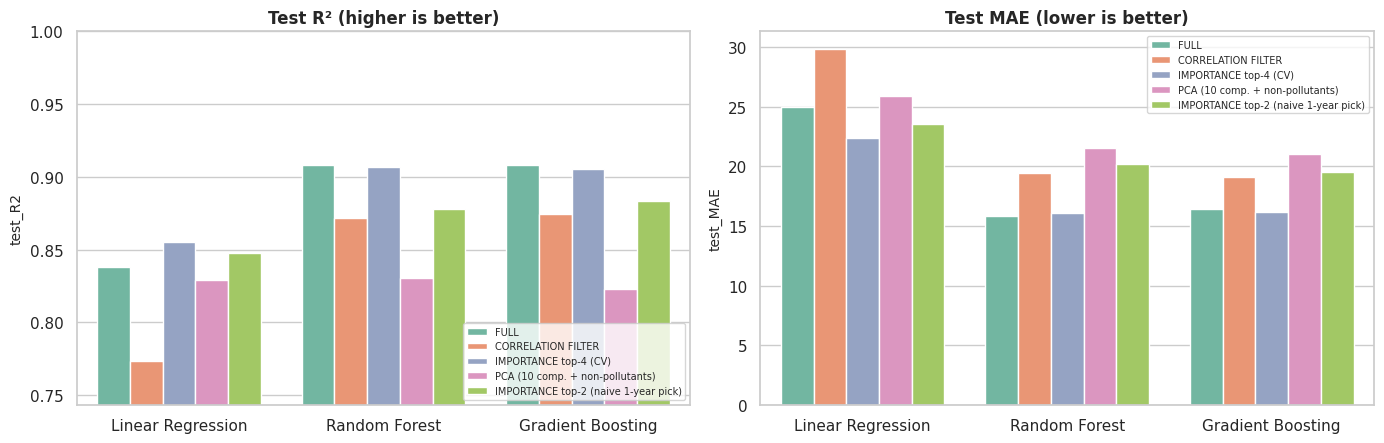

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, metric, ttl in zip(axes, ["test_R2", "test_MAE"], ["Test R² (higher is better)", "Test MAE (lower is better)"]):
    sns.barplot(data=comp, x="model", y=metric, hue="feature_set", ax=ax, palette="Set2"); ax.set_title(ttl); ax.set_xlabel(""); ax.legend(fontsize=7, loc="lower right" if "R2" in metric else "upper right")
axes[0].set_ylim(comp.test_R2.min() - 0.03, 1.0)
plt.tight_layout(); save_fig("04_feature_set_comparison"); plt.show()

## 8 · Decision
Rule (training-period time-series CV, Gradient Boosting): choose the **smallest** reduced candidate (correlation filter or importance set) whose CV R² is within **0.005** of the full model. If none qualifies, keep all features. The test period is *reported* but is not part of the rule.

In [11]:
gb = comp[comp.model == "Gradient Boosting"].set_index("feature_set")
full_cv = gb.loc["FULL", "cv_R2"]
imp_name = f"IMPORTANCE top-{k_star} (CV)"
cands = {"CORRELATION FILTER": CORR_SET, imp_name: IMP_SET}
ok_sets = {n: f for n, f in cands.items() if gb.loc[n, "cv_R2"] >= full_cv - TOL}
if ok_sets:
    chosen = min(ok_sets, key=lambda n: len(ok_sets[n])); final = ok_sets[chosen]
else:
    chosen, final = "FULL", ALL_LOGICAL
num_f, cat_f = split_cols(final)
dropped = [f for f in ALL_LOGICAL if f not in final]
sel = {"name": chosen, "numeric": num_f, "categorical": cat_f, "features": final, "dropped": dropped,
       "cv_R2_full": float(full_cv), "cv_R2_selected": float(gb.loc[chosen, "cv_R2"]) if chosen != "FULL" else float(full_cv),
       "test_R2_full": float(gb.loc["FULL", "test_R2"]), "test_R2_selected": float(gb.loc[chosen, "test_R2"]) if chosen != "FULL" else float(gb.loc["FULL", "test_R2"]),
       "test_MAE_full": float(gb.loc["FULL", "test_MAE"]), "test_MAE_selected": float(gb.loc[chosen, "test_MAE"]) if chosen != "FULL" else float(gb.loc["FULL", "test_MAE"])}
json.dump(sel, open(config.RESULTS_DIR / "selected_features.json", "w"), indent=2)
comp.to_csv(config.RESULTS_DIR / "feature_reduction_results.csv", index=False)
db.log_results(log_rows, "feature_reduction", conn); conn.close()
print(f"SELECTED: {chosen}  ({len(final)} of {len(ALL_LOGICAL)} features)")
print("kept   :", [LABELS.get(f, f) for f in final])
print("dropped:", [LABELS.get(f, f) for f in dropped])
print(f"CV R² {full_cv:.4f} → {sel['cv_R2_selected']:.4f} | test R² {sel['test_R2_full']:.4f} → {sel['test_R2_selected']:.4f} | test MAE {sel['test_MAE_full']:.1f} → {sel['test_MAE_selected']:.1f}")

SELECTED: IMPORTANCE top-4 (CV)  (4 of 23 features)
kept   : ['PM2.5', 'PM10', 'CO', 'O3']
dropped: ['NO', 'NO2', 'NOx', 'NH3', 'SO2', 'Benzene', 'Toluene', 'month_sin', 'month_cos', 'dayofweek', 'is_weekend', 'is_winter', 'is_diwali_window', 'is_holi_window', 'is_dussehra_window', 'is_stubble_season', 'is_lockdown', 'city', 'season']
CV R² 0.8559 → 0.8533 | test R² 0.9083 → 0.9052 | test MAE 16.5 → 16.2


### Conclusions of the feature analysis

1. **Yes – the feature set can be reduced dramatically.** Of 23 candidate features, **4 are enough: PM2.5, PM10, CO and O3**. Test R² moves only from 0.908 to 0.905 (Gradient Boosting) and the MAE from 16.5 to 16.2 AQI points; Random Forest is unchanged (0.908 → 0.907). That is an 83 % cut in features with no practical loss.
2. **PM2.5 and PM10 carry almost everything.** Permutation importance: shuffling PM2.5 raises the error by ~42 AQI points and PM10 by ~13; the next feature (CO) by only ~1.8. This matches the CPCB rule (AQI = max of sub-indices; particulates dominate on most days).
3. **Calendar, festival, stubble, lockdown and weekday features add nothing for *same-day* AQI** (importance ≈ 0). Not because they are irrelevant (EDA showed Diwali raises AQI by ~+33 points) but because their effect already shows up in that day's PM readings – the pollutants "explain away" the event. These features can matter for **next-day forecasting**, where tomorrow's event is not yet in tomorrow's pollutant values (tested in notebook 07). Note also that `is_lockdown` is constant (0) in the training period and can never be learned from it.
4. **A naive correlation filter *hurts* here (test R² 0.908 → 0.874).** It dropped PM10 as "redundant" with PM2.5 (ρ = 0.81) – but because the AQI is a *maximum* over pollutants, PM10 has unique information (it is the dominant pollutant in Chandigarh, Amritsar, Jaipur and Mumbai). Lesson: high correlation between two inputs does not mean one is useless when the target is a max() of them.
5. **PCA does not help either** (test R² 0.823–0.831 for the tree models): 10 components are needed for 95 % of the pollutant variance (VIFs are all < 3.4 → no severe multicollinearity), and the components capture variance, not relevance to the target. Linear Regression is the only model that stays close (0.829 vs 0.838).
6. **Selection protocol matters.** A single validation year picked only {PM2.5, PM10} and looked *better* than the full model on that year (0.859 vs 0.841), yet scored worse on the test period (0.883 vs 0.908). Time-series CV gave a stable answer (k = 4). We kept the naive result in the table for transparency.

**Decision carried forward:** the same-day models in notebooks 05 and 06 use the **4 selected features** as the main configuration and are also compared with the full feature set; the next-day models in notebook 07 start from the full set (including calendar / event features) because of finding 3.